In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Load data ──────────────────────────────────────────────────────────────
df = pd.read_csv("../data/metadata.csv", sep="|")
print(df.head())

                    file  class speaker_id  audio_number
0  data/wav/0_1088_1.wav      0       1088             1
1  data/wav/0_1088_2.wav      0       1088             2
2  data/wav/0_1088_3.wav      0       1088             3
3  data/wav/0_1088_4.wav      0       1088             4
4  data/wav/0_1088_5.wav      0       1088             5


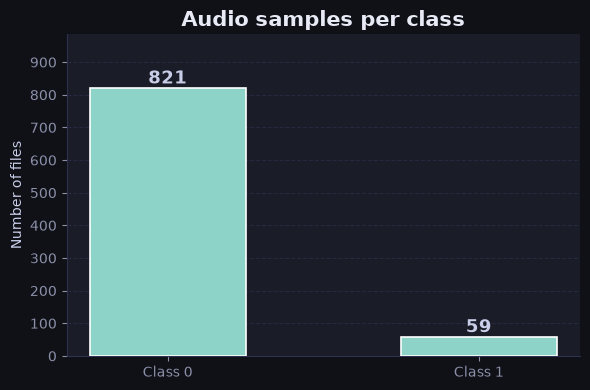

In [34]:
# ── Chart 1: audio count per class ────────────────────────────────────────
class_counts = df["class"].value_counts().sort_index()
labels = [f"Class {i}" for i in class_counts.index]

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(labels, class_counts.values, width=0.5,
              edgecolor="white", linewidth=1.2, zorder=3)

# Value labels on top of each bar
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        str(int(bar.get_height())),
        ha="center", va="bottom", fontsize=13, fontweight="bold"
    )

ax.set_title("Audio samples per class")
ax.set_ylabel("Number of files")
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(axis="y", zorder=0)
ax.set_ylim(0, class_counts.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

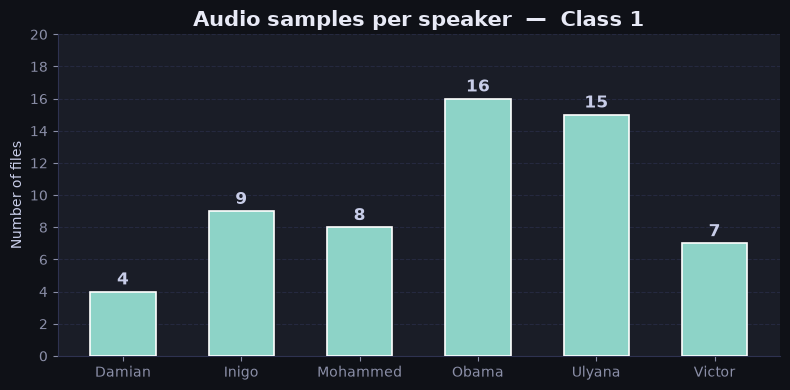

In [35]:
# ── Chart 2: audio count per speaker (class 1 only) ───────────────────────
SPEAKERS = ["Damian", "Inigo", "Mohammed", "Obama", "Ulyana", "Victor"]

class1_df = df[df["class"] == 1]
speaker_counts = (
    class1_df[class1_df["speaker_id"].isin(SPEAKERS)]
    .groupby("speaker_id", sort=False)
    .size()
    .reindex(SPEAKERS, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    speaker_counts.index, speaker_counts.values,
    width=0.55, edgecolor="white", linewidth=1.2, zorder=3
)

# Value labels
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        str(int(bar.get_height())),
        ha="center", va="bottom", fontsize=12, fontweight="bold"
    )

ax.set_title("Audio samples per speaker  —  Class 1")
ax.set_ylabel("Number of files")
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(axis="y", zorder=0)
ax.set_ylim(0, speaker_counts.max() * 1.25)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

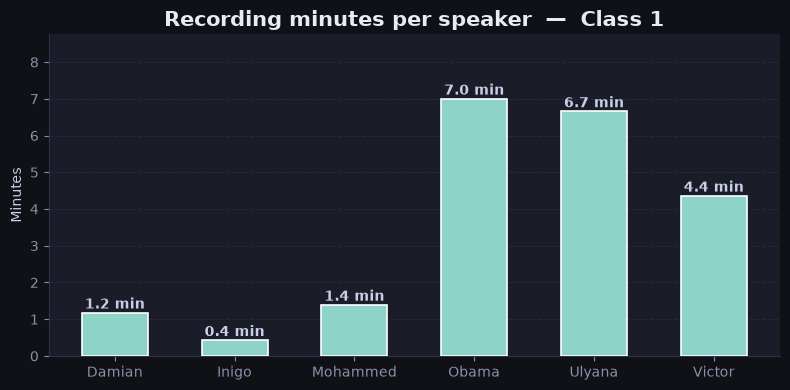

In [36]:
# ── Chart 3: recording minutes per speaker (class 1 only) ─────────────────
import wave

WAV_DIR = "../data/wav/"

def get_duration_minutes(file_path):
    """Returns duration in minutes of a WAV file using the standard library."""
    with wave.open(file_path, 'r') as wf:
        frames = wf.getnframes()
        rate   = wf.getframerate()
        return (frames / rate) / 60.0

class1_df = df[df["class"] == 1].copy()
class1_df["duration_min"] = class1_df["file"].apply(
    lambda f: get_duration_minutes(WAV_DIR + f.split("/")[-1])
)

speaker_minutes = (
    class1_df[class1_df["speaker_id"].isin(SPEAKERS)]
    .groupby("speaker_id", sort=False)["duration_min"]
    .sum()
    .reindex(SPEAKERS, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    speaker_minutes.index, speaker_minutes.values,
    width=0.55, edgecolor="white", linewidth=1.2, zorder=3
)

# Value labels (rounded to 1 decimal)
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{bar.get_height():.1f} min",
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )

ax.set_title("Recording minutes per speaker  —  Class 1")
ax.set_ylabel("Minutes")
ax.grid(axis="y", zorder=0)
ax.set_ylim(0, speaker_minutes.max() * 1.25)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

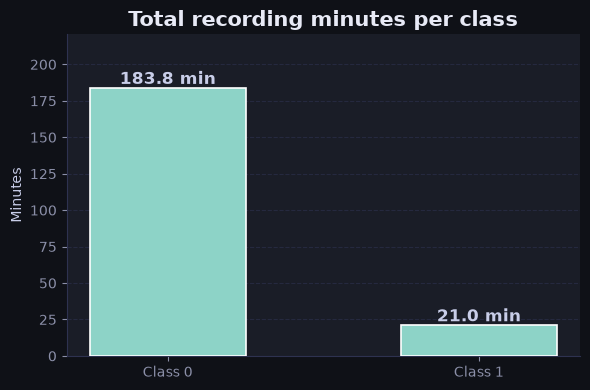

In [37]:
# ── Chart 4: total recording minutes per class ────────────────────────────
df["duration_min"] = df["file"].apply(
    lambda f: get_duration_minutes(WAV_DIR + f.split("/")[-1])
)

class_minutes = df.groupby("class")["duration_min"].sum().sort_index()
labels = [f"Class {i}" for i in class_minutes.index]

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(labels, class_minutes.values, width=0.5,
              edgecolor="white", linewidth=1.2, zorder=3)

# Value labels
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{bar.get_height():.1f} min",
        ha="center", va="bottom", fontsize=12, fontweight="bold"
    )

ax.set_title("Total recording minutes per class")
ax.set_ylabel("Minutes")
ax.grid(axis="y", zorder=0)
ax.set_ylim(0, class_minutes.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()